# Computational Physics Prac 4
Any cell starting with a \# means you should put your answer there. `Text like this` are instructions. Double click the cell, select the text in the cell, push backspace to remove the placeholder text and then type your answer. Cells can be either "Markdown", for written answers, or "Code" for actual python code. **Make sure you run each cell** with shift + enter or clicking the play button in the top left. Make sure your code actually runs and produces an output. This will be saved with the notebook. If your code produces an error which you don't manage to fix, it's ok to leave it there. 

### `Name:` 

Pride

### `Student number:` 

4503127

## Question 1

### Electromagnetic Calculations

`1.a. Put your well-commented code below and run it by pressing shift+enter`

In [6]:
import numpy as np
G = 6.674e-11
e = 1.602e-19
m_e = 9.109e-31
m_p = 1.673e-27
epsilon_0 = 8.854e-12
ratio = G*m_e*m_p*4*np.pi*epsilon_0/e**2

print("The ratio of gravitational to electrostatic force between an electron and a proton is:", ratio)

'''
Conversions:
• 1m=1015fm
• 1kg =5.61×1029MeV (the energy equivalent, from E = mc2)
• ℏc =197.3MeVfm, and in these units e2 = αℏc where α is the fine structure constant
'''

c = 3e8  # speed of light in m/s
'''
1/60 m/s: 1015 fm/s

3e8 m/s: x fm/s

x = 3e8 * (1e15) fm/s
'''
c_fm = 3e8 * (1e15)  # speed of light in fm
print("Speed of light in fm/s:", c_fm)

''' 
G = 6.674e-11 m^3 kg^-1 s^-2

1 m^3 = (1e15 fm)^3 = 1e45 fm^3
1 kg = 5.61e29 MeV

'''
G_fm = G * (1e15 ** 3) / (5.61e29) # G in fm^3 MeV^-1 s^-2

print()
print("Gravitational constant in fm^3 MeV^-1 s^-2:", G_fm)

'''
e^2 = alpha * hbar * c = 1/137 * 197.3 MeV fm
'''

alpha = 1/137
hbar_c = 197.3  # MeV fm
e2 = alpha * hbar_c  # e^2 in MeV fm
print()
print("e^2 in MeV fm:", e2)
print("Therefore, e in MeV^(1/2) fm^(1/2):", np.sqrt(e2))

'''
m_e = 9.109e-31 kg
1 kg = 5.61e29 MeV
'''
m_e_MeV = m_e * 5.61e29  # m_e in MeV
print()
print("Mass of electron in MeV:", m_e_MeV)

'''
m_p = 1.673e-27 kg
1 kg = 5.61e29 MeV
'''
m_p_MeV = m_p * 5.61e29  # m_p in MeV
print()
print("Mass of proton in MeV:", m_p_MeV) 


ratio_fm = (G_fm * m_e_MeV * m_p_MeV) / (e2 * c_fm**2)
print()
print("The ratio of gravitational to electrostatic force between" \
    " an electron and a proton in new units is:", ratio_fm)

The ratio of gravitational to electrostatic force between an electron and a proton is: 4.40937670661483e-40
Speed of light in fm/s: 3e+23

Gravitational constant in fm^3 MeV^-1 s^-2: 118966.13190730836

e^2 in MeV fm: 1.44014598540146
Therefore, e in MeV^(1/2) fm^(1/2): 1.2000608257090388

Mass of electron in MeV: 0.5110148999999999

Mass of proton in MeV: 938.5530000000001

The ratio of gravitational to electrostatic force between an electron and a proton in new units is: 4.402168674648659e-40


`1.b. Report the value of each converted constant and the ratio below.`

The ratio of gravitational to electrostatic force between an electron and a proton is: 4.40937670661483e-40
Speed of light in fm/s: 3e+23

Gravitational constant in fm^3 MeV^-1 s^-2: 118966.13190730836

e^2 in MeV fm: 1.44014598540146
Therefore, e in MeV^(1/2) fm^(1/2): 1.2000608257090388

Mass of electron in MeV: 0.5110148999999999

Mass of proton in MeV: 938.5530000000001

The ratio of gravitational to electrostatic force between an electron and a proton in new units is: 4.402168674648659e-40

`2. Compare your answer with the SI version. Do they agree, and should you have expected them to?`

My answer agrees, and we expect them to because the ratio of gravitational to electrostatic force is a dimensionless quantity.

----------------------------

## Question 2

### Electric field lines

In [7]:
# Run this cell before you start Question 2.
# It sets up the grid and the plotting function you need for this question. Don't change it.
import numpy as np
import matplotlib.pyplot as plt

# The grid of points to calculate the field on
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)

def plot_field_lines(X, Y, Ex, Ey, charges):
    # Plots the electric field lines on the grid X, Y
    # Ex and Ey are the x and y components of the electric field at every point on the grid
    # charges is a list of the charges, each one written as [q, x0, y0]

    # Start the field lines on a small circle around each charge
    start_points = []
    for q, x0, y0 in charges:
        for angle in np.linspace(0, 2*np.pi, 16, endpoint=False):
            start_points.append([x0 + 0.1*np.cos(angle), y0 + 0.1*np.sin(angle)])

    # Draw the field lines
    plt.figure(figsize=(5, 5))
    plt.streamplot(X, Y, Ex, Ey, start_points=start_points, color='k', linewidth=0.8,
                   broken_streamlines=False)
    # Mark the charges: red for positive, blue for negative
    for q, x0, y0 in charges:
        if q > 0:
            plt.plot(x0, y0, 'or')
        else:
            plt.plot(x0, y0, 'ob')
    plt.xlim(-3, 3)
    plt.ylim(-3, 3)
    plt.gca().set_aspect('equal')
    plt.xlabel('x (m)')
    plt.ylabel('y (m)')

`1. Put your well-commented code to make the plot below. Be sure to run your notebook so the plot appears!`

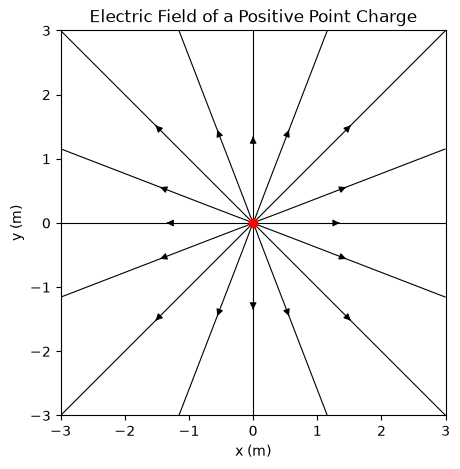

In [9]:
def E_point(X, Y, q, x0, y0): 
    k = 8.99e9

    r = np.sqrt((X - x0)**2 + (Y - y0)**2)

    Ex = k * q * (X - x0) / r**3
    Ey = k * q * (Y - y0) / r**3

    return Ex, Ey

charges = [[1e-9, 0, 0]]

Ex, Ey = E_point(X, Y, 1e-9, 0, 0)

plot_field_lines(X, Y, Ex, Ey, charges)

plt.title("Electric Field of a Positive Point Charge")
plt.show()

`2. Put your well-commented code to make the plot below. Be sure to run your notebook so the plot appears!`

`3. Put your well-commented code to make the plot below. Be sure to run your notebook so the plot appears!`

In [ ]:
# Put your code here

----------------------------

## Question 3

### LLM Chat History

`Submit your LLM chat history or other resources you used as per instructions given in class.`

----------------------------

## Instructions checklist

- Fill in the feedback form if requested (see iKamva)
- Make sure you use this template notebook and not a new file
- Rename your file with `<your_student_number>_prac4.ipynb`
- Submit to iKamva

----------------------------